# Дисперсионный анализ (ANOVA / MANOVA) в Python

**Дисциплина:** Введение в анализ больших данных

**ANOVA** проверяет H0: средние отклика одинаковы по уровням фактора(ов).

- однофакторный: одна категориальная независимая;
- двухфакторный: два фактора + взаимодействие (`y ~ A * B`);
- **MANOVA**: несколько зависимых переменных сразу.

Инструменты: `statsmodels` (`ols`, `anova_lm`, `MANOVA`).

Демо: **tips** и **penguins**.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.multivariate.manova import MANOVA

plt.rcParams["figure.figsize"] = (10, 6)
sns.set_style("whitegrid")


---
## 1. Двухфакторный ANOVA

Отклик `tip`, факторы `day` и `time` (датасет tips).

Формула `tip ~ day * time` = главные эффекты + взаимодействие.


In [12]:
da = pd.read_csv('DA.csv', sep=';', encoding='cp1251')
da.head()

,region,conditions,view,priming,weight
0,Русский,Аквакультура,серый,камни,85.9
1,Русский,Естественные,черный,камни,99.3
2,Русский,Аквакультура,черный,камни,119.8
3,Русский,Естественные,серый,камни,115.5
4,Русский,Аквакультура,серый,песок,88.9


In [22]:
print(da.groupby(['priming', 'view'])['weight'].agg(['mean', 'std', 'count']).round(2))

                  mean    std  count
priming view                        
ил      серый   151.72  33.08      6
        черный  161.27  27.57      6
камни   серый    99.08  11.42      6
        черный  139.65  39.61      6
песок   серый   131.70  30.77      6
        черный  122.67  61.58      6


In [21]:
model_1 = smf.ols('weight ~ C(priming) * C(view)', data=da).fit()
print("=== ANOVA: priming x view ===")
print(anova_lm(model_1, typ=3))


=== ANOVA: priming x view ===
                           sum_sq    df          F        PR(>F)
Intercept           138107.681667   1.0  99.925491  4.615133e-11
C(priming)            8469.563333   2.0   3.064005  6.154010e-02
C(view)                273.607500   1.0   0.197964  6.595630e-01
C(priming):C(view)    3767.533889   2.0   1.362968  2.712925e-01
Residual             41463.198333  30.0        NaN           NaN


In [20]:
model_2 = smf.ols('weight ~ C(priming) * C(region)', data=da).fit()
print("=== ANOVA: priming x region ===")
print(anova_lm(model_2, typ=3))

=== ANOVA: priming x region ===
                            sum_sq    df          F        PR(>F)
Intercept             84187.022500   1.0  65.347924  1.100232e-08
C(priming)             2263.166667   2.0   0.878361  4.270012e-01
C(region)               788.521667   2.0   0.306034  7.388819e-01
C(priming):C(region)   6284.057778   4.0   1.219458  3.257205e-01
Residual              34783.807500  27.0        NaN           NaN


In [19]:
model_3 = smf.ols('weight ~ C(priming) * C(conditions)', data=da).fit()
print("=== ANOVA: priming x conditions ===")
print(anova_lm(model_3, typ=3))

=== ANOVA: priming x conditions ===
                                 sum_sq    df          F        PR(>F)
Intercept                 132135.360000   1.0  92.399338  1.139310e-10
C(priming)                  5196.014444   2.0   1.816729  1.799890e-01
C(conditions)                785.700833   1.0   0.549423  4.643166e-01
C(priming):C(conditions)     435.151667   2.0   0.152146  8.595214e-01
Residual                   42901.398333  30.0        NaN           NaN


**Чтение таблицы ANOVA**

- для каждой строки: Sum Sq, F, PR(>F);
- p < 0.05 → эффект **значим**;

sum_sq - сумма отклонений в квадрате (вклад фактора и остатков)

df - степени свободы

F-статистика - отношение фактора к остаткам

(1) $$F = \frac{MeanSq_{фактора}}{MeanSq_{остатков}} = \frac{(sumsq_{фактора} / df_{фактора})}{(sumsq_{остатков} / df_{остатков})}$$

PR(>F) - p-value


### Выводы

Разберём полученные значения от моделей. Будем смотреть только на F и p-value
> sum_sq и df нужны только для вычисления


model_1:
| источник | F | p |
|--------|-----|-|
| C(priming) | 3.06 | 0.0615 |
| C(view)| 0.2 | 0.6596 |
| Взаимодействие | 1.36 | 0.2713 |

model_2:
| источник | F | p |
|--------|-----|-|
| C(priming) | 0.88 | 0.4270 |
| C(region)| 0.31 | 0.7389 |
| Взаимодействие | 1.22 | 0.3257 |

model_3:
| источник | F | p |
|--------|-----|-|
| C(priming) | 1.82 | 0.1799 |
| C(conditions)| 0.55 | 0.4643 |
| Взаимодействие | 0.15 | 0.8595 |

$H_0$: Фактор не влияет на отклик

В каждой таблице p > 0.05, значит нулевая гипотеза не отвергается


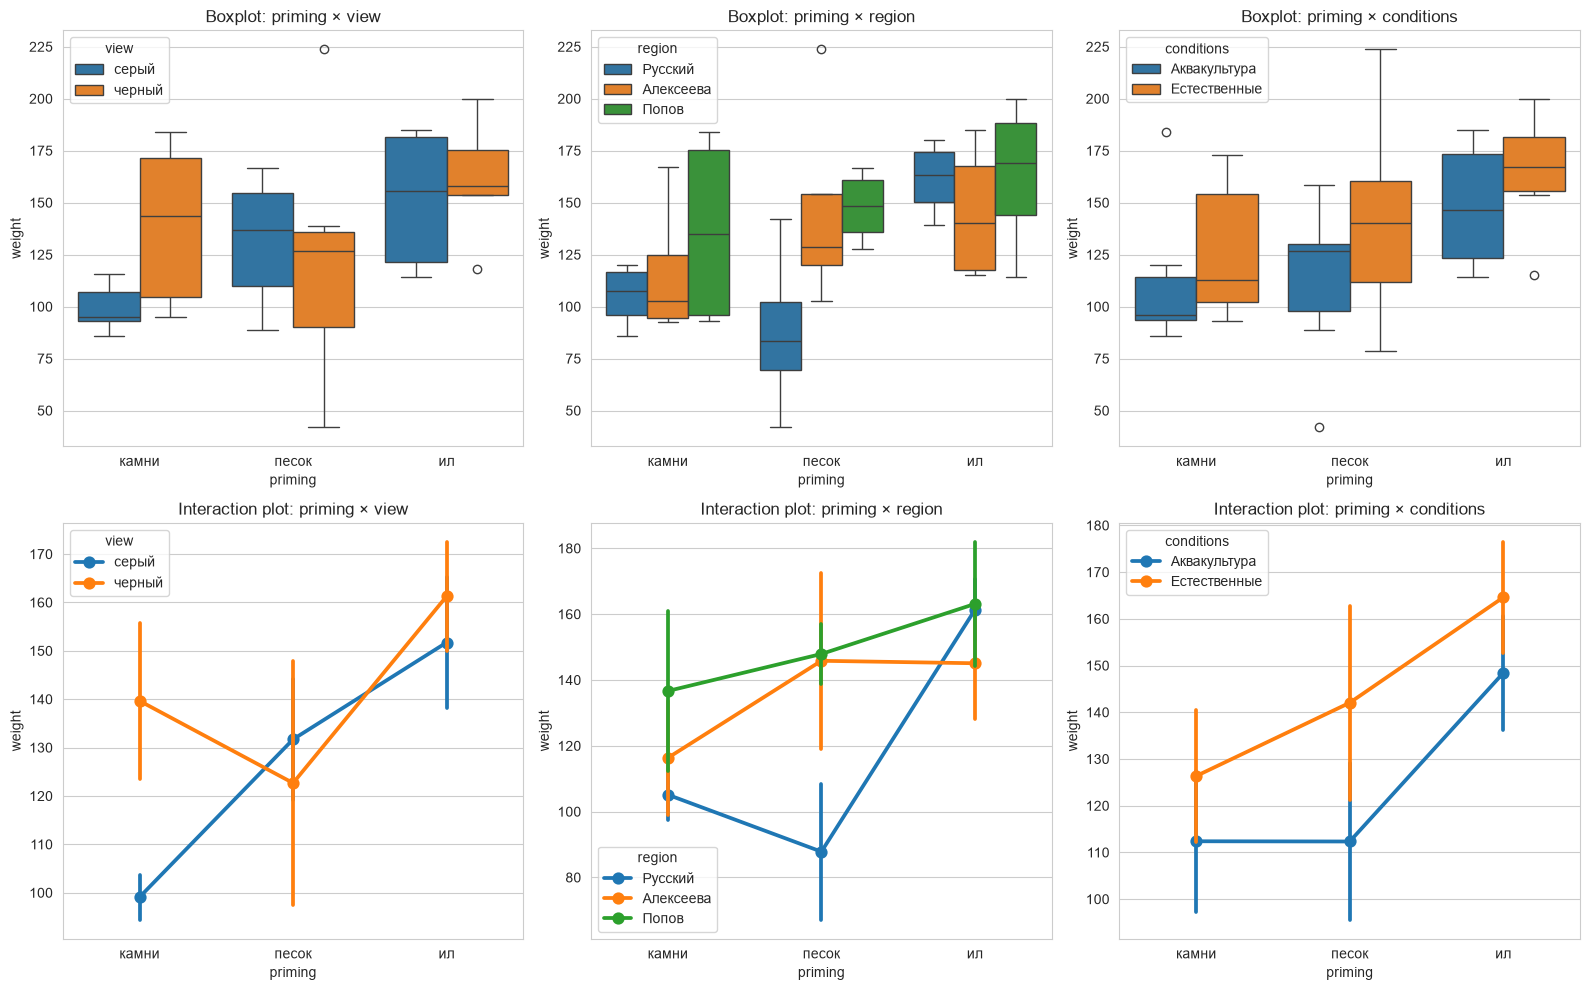

In [23]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

pairs = [('view', 'priming × view'),
         ('region', 'priming × region'),
         ('conditions', 'priming × conditions')]

for i, (factor, title) in enumerate(pairs):
    # Boxplot
    sns.boxplot(data=da, x='priming', y='weight', hue=factor, ax=axes[0, i])
    axes[0, i].set_title(f'Boxplot: {title}')

    # Interaction plot (средние ± SE)
    sns.pointplot(data=da, x='priming', y='weight', hue=factor,
                  errorbar='se', ax=axes[1, i])
    axes[1, i].set_title(f'Interaction plot: {title}')

plt.tight_layout()
plt.show()


По графикам boxplot кажется, что в каждом есть место для наличия влияния на вес, однако это не так, ведь мы уже выяснили, что такие результаты статистически незначимы.

---
## 3. MANOVA

Несколько зависимых переменных одновременно.  
H0: векторы средних одинаковы по группам.


In [25]:
univ = pd.read_csv('university2.csv', sep=';')
univ.head()

,mesto2016,mesto2015,Reyt_funcz,Yslov_educ,Yslov_job,Yslov_science,University
0,1,1,"4,59",1,2,1,1
1,2,2,"4,46",3,3,3,2
2,3,3,"4,24",7,6,2,3
3,4,4,"4,08",10,1,14,4
4,5,6,"4,07",5,12,6,5


In [26]:
univ['University'] = univ['University'].astype('category')

In [28]:
ys = ['Yslov_educ', 'Yslov_job', 'Yslov_science']

print("Средние по University:")
print(univ.groupby('University')[ys].mean().round(2))

Средние по University:
            Yslov_educ  Yslov_job  Yslov_science
University                                      
1                  1.0        2.0            1.0
2                  3.0        3.0            3.0
3                  7.0        6.0            2.0
4                 10.0        1.0           14.0
5                  5.0       12.0            6.0
...                ...        ...            ...
79                70.0       57.0          111.0
80                57.0      131.0           49.0
81                87.0       53.0           98.0
82                82.0       83.0           65.0
83                93.0       43.0          130.0

[83 rows x 3 columns]


In [29]:
formula = 'Yslov_educ + Yslov_job + Yslov_science ~ C(University)'
maov = MANOVA.from_formula(formula, data=univ)
print(maov.mv_test())


                           Multivariate linear model
                                                                                
--------------------------------------------------------------------------------
       Intercept             Value       Num DF  Den DF      F Value      Pr > F
--------------------------------------------------------------------------------
          Wilks' lambda           0.0000 3.0000 -2.0000 -13474068570.5198    nan
         Pillai's trace           1.0000 3.0000 -2.0000 -13474068570.5198    nan
 Hotelling-Lawley trace 20211102855.7797 3.0000 -1.0000  -6737034285.2599    nan
    Roy's greatest root 20211102855.7797 3.0000 -2.0000 -13474068570.5198    nan
--------------------------------------------------------------------------------
                                                                                
-----------------------------------------------------------------------------------
          C(University)         Value      Num DF    

A:\vvsuProjects\bigdata\.venv\Lib\site-packages\statsmodels\multivariate\multivariate_ols.py:184: RuntimeWarning: divide by zero encountered in scalar divide
  eigv1 = np.array([i / (1 - i) for i in eigv2])
A:\vvsuProjects\bigdata\.venv\Lib\site-packages\statsmodels\multivariate\multivariate_ols.py:184: RuntimeWarning: invalid value encountered in scalar divide
  eigv1 = np.array([i / (1 - i) for i in eigv2])
A:\vvsuProjects\bigdata\.venv\Lib\site-packages\statsmodels\multivariate\multivariate_ols.py:215: RuntimeWarning: divide by zero encountered in scalar divide
  F = (1 - lmd) / lmd * df2 / df1
A:\vvsuProjects\bigdata\.venv\Lib\site-packages\statsmodels\multivariate\multivariate_ols.py:253: RuntimeWarning: invalid value encountered in scalar multiply
  F = df2 / df1 * sigma


###### Предупреждения не просто так, в данных все записи по университетам уникальны, то есть на один университет выделено по 1 строке - это создаёт проблемы для работы MANOVA, потому что мы не сможем найти разброс внутри групп, если там выборка размерностью 1

После значимого MANOVA смотрят **одномерные** ANOVA по каждой y.


In [31]:
univ['Uni_Tier'] = pd.qcut(univ['Yslov_educ'].rank(method='first'), q=3, labels=['Топ-28', 'Середняки (29-56)', 'Аутсайдеры (57+)'])

print("\nРаспределение университетов по новым группам:")
print(univ['Uni_Tier'].value_counts())

# 3. Смотрим средние значения рейтингов уже по этим ГРУППАМ
ys = ['Yslov_educ', 'Yslov_job', 'Yslov_science']
print("\nСредние значения рейтингов по группам (Uni_Tier):")
print(univ.groupby('Uni_Tier')[ys].mean().round(2))

# 4. Запускаем MANOVA для новой группировки!
formula_fixed = 'Yslov_educ + Yslov_job + Yslov_science ~ C(Uni_Tier)'
maov_fixed = MANOVA.from_formula(formula_fixed, data=univ)

print("\n=== Результаты MANOVA (по группам университетов) ===")
print(maov_fixed.mv_test())


Распределение университетов по новым группам:
Uni_Tier
Топ-28               28
Аутсайдеры (57+)     28
Середняки (29-56)    27
Name: count, dtype: int64

Средние значения рейтингов по группам (Uni_Tier):
                   Yslov_educ  Yslov_job  Yslov_science
Uni_Tier                                               
Топ-28                  14.50      22.43          27.04
Середняки (29-56)       42.11      63.85          49.19
Аутсайдеры (57+)        77.04      57.18          71.86

=== Результаты MANOVA (по группам университетов) ===
                  Multivariate linear model
                                                              
--------------------------------------------------------------
         Intercept        Value  Num DF  Den DF F Value Pr > F
--------------------------------------------------------------
            Wilks' lambda 0.5172 3.0000 78.0000 24.2739 0.0000
           Pillai's trace 0.4828 3.0000 78.0000 24.2739 0.0000
   Hotelling-Lawley trace 0.9336 3.0000

### Вывод
Разберём Wilks' lambda и Pillai's trace:
> Все результаты статистически значимы (Pr > F) < 0.05

Wilks' lambda = 0.127, хороший показатель (Чем ближе к 0, тем лучше). Показывает необъяснённую дисперсию, а у нас как раз всего 12,7%, остальное объясняется группами `Uni_Tier`

След Пиллая = 1.0179, Сумма объяснённых дисперсий по всем каноническим корням. Чем ближе к числу зависимых переменных, а у нас их 3, тем лучше.



In [33]:
print("=== Одномерные ANOVA ===")
for y in ys:
    m = smf.ols(f"{y} ~ C(Uni_Tier)", data=univ).fit()
    print(f"\n{y}:")
    print(anova_lm(m, typ=2))


=== Одномерные ANOVA ===

Yslov_educ:
                   sum_sq    df           F        PR(>F)
C(Uni_Tier)  54993.610011   2.0  217.524442  4.463356e-33
Residual     10112.630952  80.0         NaN           NaN

Yslov_job:
                   sum_sq    df          F        PR(>F)
C(Uni_Tier)  27441.049994   2.0  17.653684  4.459819e-07
Residual     62176.371693  80.0        NaN           NaN

Yslov_science:
                   sum_sq    df          F        PR(>F)
C(Uni_Tier)  28126.689695   2.0  16.544998  9.696878e-07
Residual     68000.466931  80.0        NaN           NaN


sum_sq - сумма отклонений в квадрате (вклад фактора и остатков)

df - степени свободы

F-статистика - отношение фактора к остаткам

(1) $$F = \frac{MeanSq_{фактора}}{MeanSq_{остатков}} = \frac{(sumsq_{фактора} / df_{фактора})}{(sumsq_{остатков} / df_{остатков})}$$

PR(>F) - p-value

F-стат для образования очень большой = 217.5, это говорит о том, что разница между группами в 217 раз больше, чем разброс внутри групп,

Остальные поменьше, но не менее значимы.

$H_0$: Средние значения зависимой переменной одинаковы во всех группах фактора.

Тем не менее, p-value везде сильно меньше 0.05, значит нулевая гипотеза отвергается, мы даже по колоссальному разрыву в 217 раз видим это, плюс эти результаты значимы и шанс их случайности - много нулей

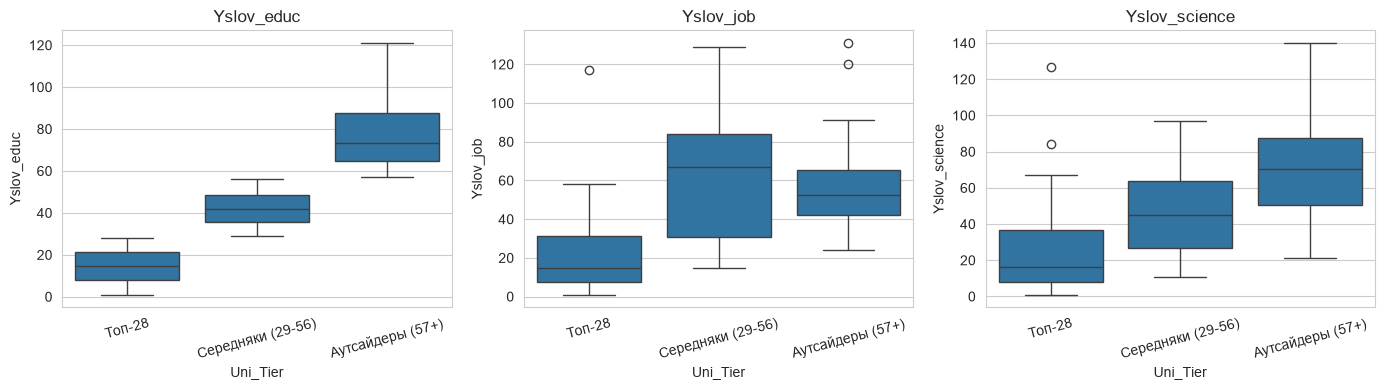

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, y in zip(axes, ys):
    sns.boxplot(data=univ, x="Uni_Tier", y=y, ax=ax)
    ax.set_title(y)
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()


### Как описать результаты

1. **ANOVA:** для A, B, A:B — F и p; p < 0.05 → эффект значим.  
2. Значимое взаимодействие — влияние одного фактора меняется по уровням другого.  
3. **MANOVA:** p < 0.05 → группы различаются в пространстве нескольких откликов.  
4. Затем — одномерные ANOVA и графики (boxplot / pointplot).

---
## Шпаргалка по методам (Python)

| Задача | Код |
|--------|-----|
| ANOVA-модель | `smf.ols("y ~ A * B", data=df).fit()` |
| Таблица ANOVA | `anova_lm(model, typ=2)` |
| Средние по группам | `df.groupby(["A","B"])["y"].mean()` |
| MANOVA | `MANOVA.from_formula("y1 + y2 ~ F", data=df)` |
| Результат MANOVA | `maov.mv_test()` |
| Interaction plot | `sns.pointplot(..., hue=...)` |

---
## Что сделать после лекции

1. Откройте лабораторное задание и выполните ANOVA/MANOVA **самостоятельно** на своих CSV.  
2. Факторы удобно кодировать как `category`.

Удачи!
